In [1]:
from lights.models import Model
from lights.fits import profile_logLL_scan
from lights.plotting import plot_combined_lines, plot_contours, setup_style
from lights.paths import PLOTS_DIR

import numpy as np
import matplotlib.pyplot as plt

SAVE_DIR = PLOTS_DIR / "coupling_fits"
setup_style()

In [2]:
def contour_figure(scan, scale, xlabel, ylabel, mass_label, title, file, compare = None, **contour_options):
    """Single-panel figure of a coupling scan: Belle II, BaBar (LEP) and combined contours, with legends.

    scale: the value of the plotted coupling combinations per unit coupling multiplier, for the
    x and y axes; mass_label: format string for the mass of model_1; contour_options are
    passed to plot_contours (lep, color, shades). compare: the same scan with the other Belle II
    likelihood, whose combined contours are overlaid as lines.
    """
    fig, axes = plt.subplots(nrows = 1, ncols = 1)
    for slope in (1, -1):     # guides along |x| = |y|
        axes.axline((0, 0), slope = slope, ls = '--', color = 'grey', alpha = 0.2)
    if compare is not None:
        contour_options.setdefault("combined_label", "Combined, Belle II public")
    handles = plot_contours(axes, scan, scale, **contour_options)
    if compare is not None:
        handles["Combined, lights"] = plot_combined_lines(axes, compare, scale)

    plt.ticklabel_format(style = 'sci', axis = 'both', scilimits = (0, 0))
    axes.set_xlabel(xlabel, fontsize = 24)
    axes.set_ylabel(ylabel, fontsize = 24)

    blank, = axes.plot([], [], linewidth = 0)
    leg1 = axes.legend([blank], [mass_label % scan.models[0].mX], loc = 'upper right', fontsize = 14, frameon = True,
                       handlelength = 0, handletextpad = 0)
    axes.legend(list(handles.values()), list(handles), loc = 'lower left', fontsize = 14, frameon = True)
    axes.add_artist(leg1)

    plt.title(title, fontsize = 15)
    fig.set_size_inches(6, 6)
    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')

In [3]:
def public(scan):
    "The same coupling scan with Belle II's public likelihood for the Belle II and combined grids."
    return profile_logLL_scan(*scan.models, scan.x1[[0, -1]], scan.x2[[0, -1]], pts = (len(scan.x1), len(scan.x2)),
                              belle2 = "public")

# Two-body scenarios

Each figure scans the coupling multipliers of two models (`profile_logLL_scan`) with the SM signal fixed ($\mu_{\rm SM} = 1$) and all other couplings zero: the contours are slices through the coupling space, for a scenario with only these two couplings, not profiles over further couplings (only the nuisance parameters are profiled). The weak effective theory fits at the end profile instead.

In [4]:
Npts = [100, 100]

model_1 = Model("phi", mX = 2.1, CSL = 1e-8/2, CSR = 1e-8/2)
model_2 = Model("phi", mX = 2.1, CSL = 1e-8/2, CSR = -1e-8/2)

scan_gSgP = profile_logLL_scan(model_1, model_2, [-8, 8], [-30, 30], pts = Npts)

phi, mX = 2.1: 100%|██████████| 10000/10000 [00:10<00:00, 962.51it/s]


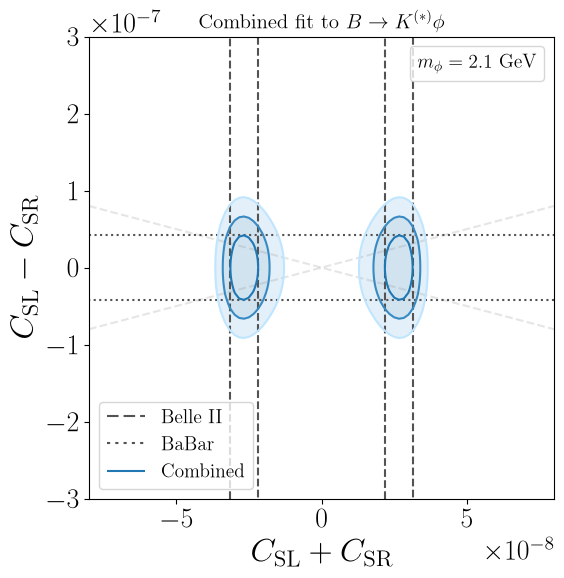

In [5]:
contour_figure(scan_gSgP, (1e-8, 1e-8), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi$', "2body_scalar_scalarcoupling.pdf", shades = 6)

With Belle II's public likelihood (dash-dot: the combined fit with the lights Belle II likelihood):

phi, mX = 2.1: 100%|██████████| 10000/10000 [00:12<00:00, 822.30it/s]


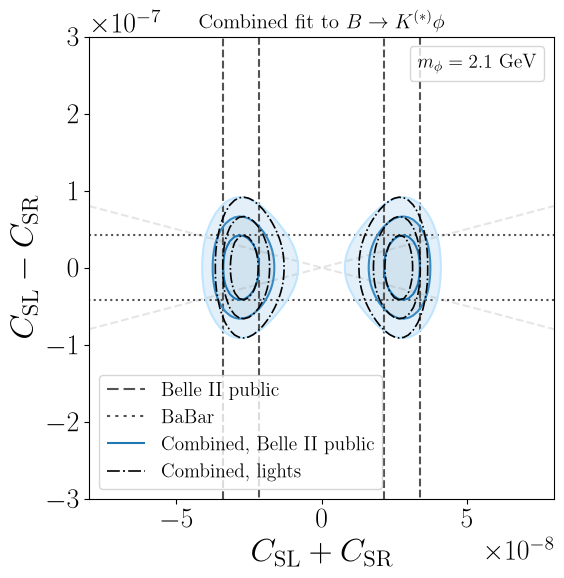

In [6]:
scan_gSgP_public = public(scan_gSgP)
contour_figure(scan_gSgP_public, (1e-8, 1e-8), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi$', "2body_scalar_scalarcoupling_public.pdf", shades = 6,
               compare = scan_gSgP)

In [7]:
Npts = [100, 100]

model_1 = Model("V", mX = 2.1, CVL = 1e-8/2, CVR = 1e-8/2)
model_2 = Model("V", mX = 2.1, CVL = 1e-8/2, CVR = -1e-8/2)

scan_hVhA = profile_logLL_scan(model_1, model_2, [-3, 3], [-8, 8], pts = Npts)

V, mX = 2.1: 100%|██████████| 10000/10000 [00:05<00:00, 1915.05it/s]


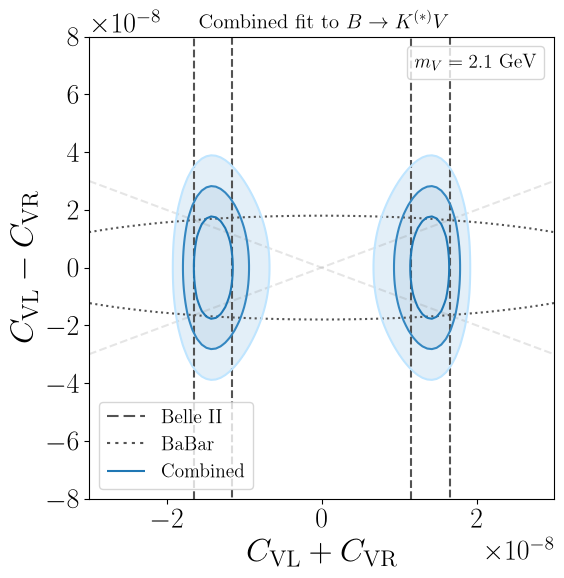

In [8]:
contour_figure(scan_hVhA, (1e-8, 1e-8), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_vectorcoupling.pdf", shades = 200)

With Belle II's public likelihood (dash-dot: the combined fit with the lights Belle II likelihood):

V, mX = 2.1: 100%|██████████| 10000/10000 [00:08<00:00, 1223.80it/s]


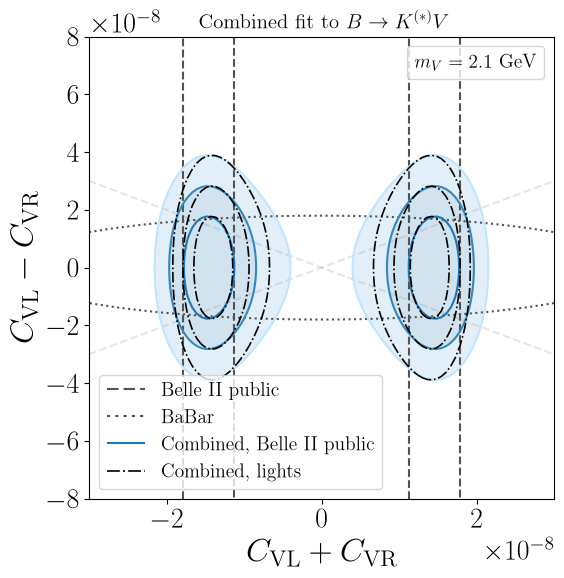

In [9]:
scan_hVhA_public = public(scan_hVhA)
contour_figure(scan_hVhA_public, (1e-8, 1e-8), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_vectorcoupling_public.pdf", shades = 200,
               compare = scan_hVhA)

In [10]:
Npts = [100, 100]

model_1 = Model("V", mX = 2.1, Lambda = 1e4, CTL = 1e-4/2, CTR = 1e-4/2)
model_2 = Model("V", mX = 2.1, Lambda = 1e4, CTL = 1e-4/2, CTR = -1e-4/2)

scan_hThTt = profile_logLL_scan(model_1, model_2, [-2, 2], [-2, 2], pts = Npts)

V, mX = 2.1: 100%|██████████| 10000/10000 [00:05<00:00, 1987.35it/s]


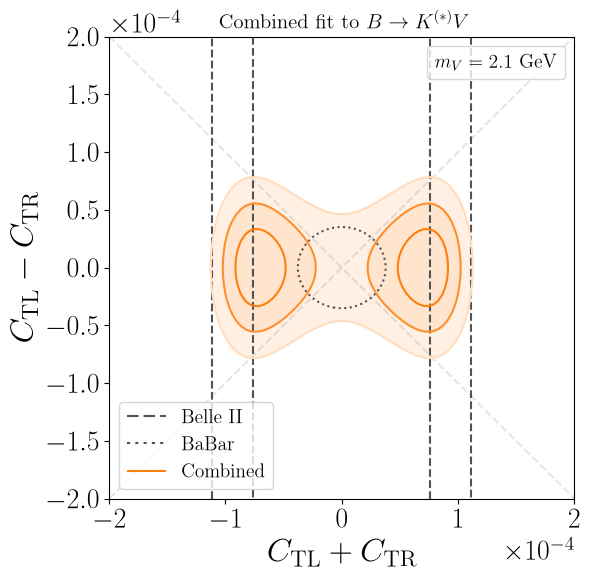

In [11]:
contour_figure(scan_hThTt, (1e-4, 1e-4), r'$C_{\rm TL} + C_{\rm TR}$', r'$C_{\rm TL} - C_{\rm TR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_tensorcoupling.pdf", color = 1, shades = 200)

With Belle II's public likelihood (dash-dot: the combined fit with the lights Belle II likelihood):

V, mX = 2.1: 100%|██████████| 10000/10000 [00:08<00:00, 1223.47it/s]


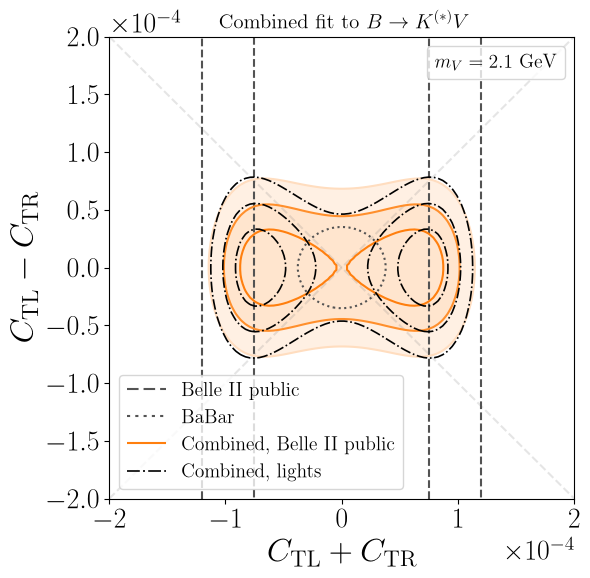

In [12]:
scan_hThTt_public = public(scan_hThTt)
contour_figure(scan_hThTt_public, (1e-4, 1e-4), r'$C_{\rm TL} + C_{\rm TR}$', r'$C_{\rm TL} - C_{\rm TR}$', r'$m_V = %1.1f$ GeV',
               r'Combined fit to $B\to K^{(*)} V$', "2body_vector_tensorcoupling_public.pdf", color = 1, shades = 200,
               compare = scan_hThTt)

# Three-body scenarios

As for the two-body scenarios, each figure scans the coupling multipliers of two models (`profile_logLL_scan`) with the SM signal fixed ($\mu_{\rm SM} = 1$) and all other couplings zero: the contours are slices through the coupling space, for a scenario with only these two couplings, not profiles over further couplings (only the nuisance parameters are profiled). The weak effective theory fits at the end profile instead.

In [13]:
Npts = [100, 100]

model_1 = Model("phiphi", mX = 0.52, Lambda = 1e4, CSL = 1e-3/2, CSR = 1e-3/2)
model_2 = Model("phiphi", mX = 0.52, Lambda = 1e4, CSL = 1e-3/2, CSR = -1e-3/2)

scan_gSSgPS = profile_logLL_scan(model_1, model_2, [-6, 6], [-10, 10], pts = Npts)

phiphi, mX = 0.52: 100%|██████████| 10000/10000 [00:05<00:00, 1930.58it/s]


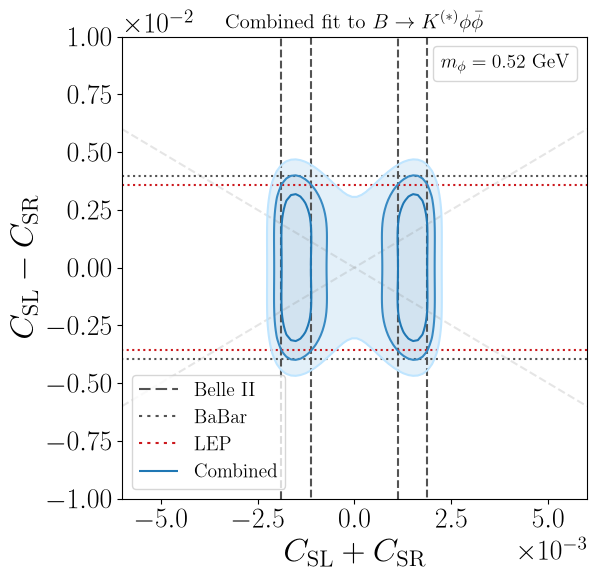

In [14]:
contour_figure(scan_gSSgPS, (1e-3, 1e-3), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_scalarcoupling.pdf", lep = True, shades = 6)

With Belle II's public likelihood (dash-dot: the combined fit with the lights Belle II likelihood):

phiphi, mX = 0.52: 100%|██████████| 10000/10000 [00:09<00:00, 1074.56it/s]


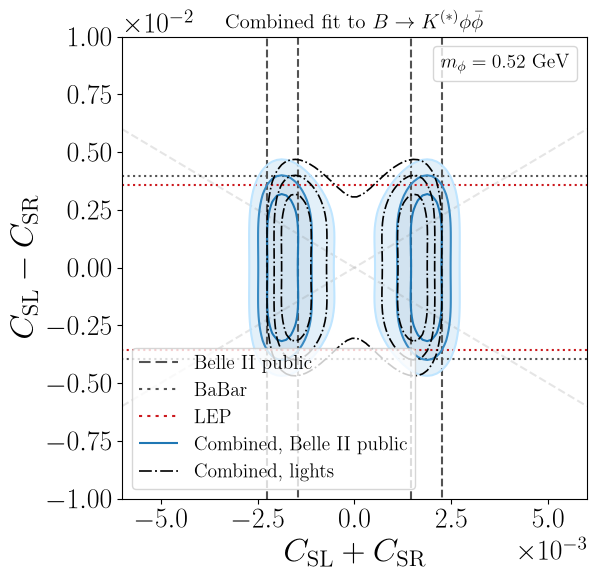

In [15]:
scan_gSSgPS_public = public(scan_gSSgPS)
contour_figure(scan_gSSgPS_public, (1e-3, 1e-3), r'$C_{\rm SL} + C_{\rm SR}$', r'$C_{\rm SL} - C_{\rm SR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_scalarcoupling_public.pdf", lep = True, shades = 6,
               compare = scan_gSSgPS)

In [16]:
Npts = [100, 100]

model_1 = Model("phiphi", mX = 0.38, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("phiphi", mX = 0.38, Lambda = 1e4, CVL = 1/2, CVR = -1/2)

scan_gVVgAV = profile_logLL_scan(model_1, model_2, [-20, 20], [-40, 40], pts = Npts)

phiphi, mX = 0.38: 100%|██████████| 10000/10000 [00:05<00:00, 1949.13it/s]


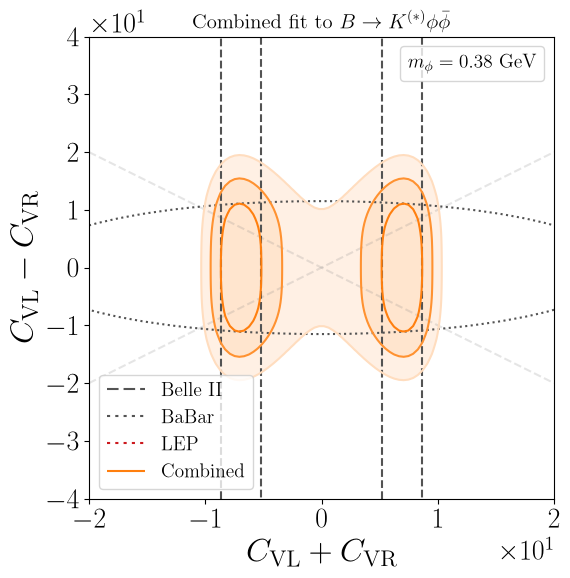

In [17]:
contour_figure(scan_gVVgAV, (1, 1), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_vectorcoupling.pdf", lep = True, color = 1, shades = 6)

With Belle II's public likelihood (dash-dot: the combined fit with the lights Belle II likelihood):

phiphi, mX = 0.38: 100%|██████████| 10000/10000 [00:08<00:00, 1143.98it/s]


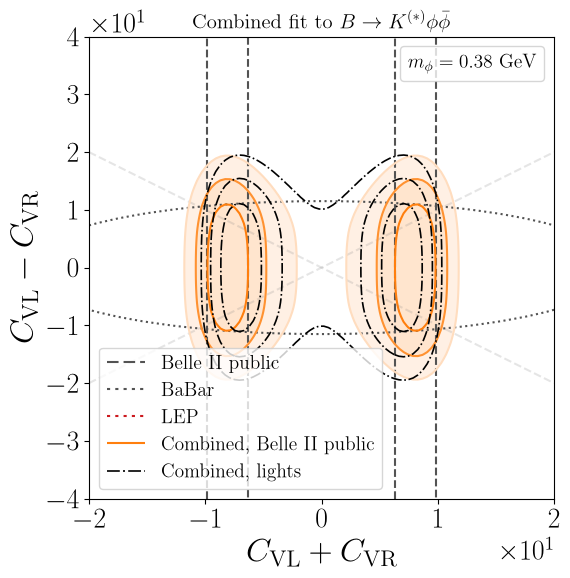

In [18]:
scan_gVVgAV_public = public(scan_gVVgAV)
contour_figure(scan_gVVgAV_public, (1, 1), r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$', r'$m_\phi = %1.2f$ GeV',
               r'Combined fit to $B\to K^{(*)} \phi \bar{\phi}$', "3body_scalar_vectorcoupling_public.pdf", lep = True, color = 1, shades = 6,
               compare = scan_gVVgAV)

In [19]:
# fVV - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fVVfVA = profile_logLL_scan(model_1, model_2, [-6, 6], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1875.66it/s]


In [20]:
# fVV - fAV
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)

scan_fVVfAV = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1803.88it/s]


In [21]:
# fVV - fAA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)

scan_fVVfAA = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1816.54it/s]


In [22]:
# fAV - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fAVfVA = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1966.78it/s]


In [23]:
# fAV - fAA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)

scan_fAVfAA = profile_logLL_scan(model_1, model_2, [-12, 12], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1884.28it/s]


In [24]:
# fAA - fVA
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, CVLp = 1/2, CVRp = 1/2)

scan_fAAfVA = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2006.69it/s]


In [25]:
# fVV - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fVVfVA_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:04<00:00, 2009.35it/s]


In [26]:
# fVV - fAV Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)

scan_fVVfAV_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1989.46it/s]


In [27]:
# fVV - fAA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = 1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)

scan_fVVfAA_M = profile_logLL_scan(model_1, model_2, [-6, 6], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1758.79it/s]


In [28]:
# fAV - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fAVfVA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1962.54it/s]


In [29]:
# fAV - fAA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVL = 1/2, CVR = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)

scan_fAVfAA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-12, 12], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1968.96it/s]


In [30]:
# fAA - fVA Majorana
Npts = [100, 100]

model_1 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = -1/2)
model_2 = Model("psipsi", mX = 0.6, Lambda = 1e4, is_ident = True, CVLp = 1/2, CVRp = 1/2)

scan_fAAfVA_M = profile_logLL_scan(model_1, model_2, [-12, 12], [-6, 6], pts = Npts)

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:05<00:00, 1948.06it/s]


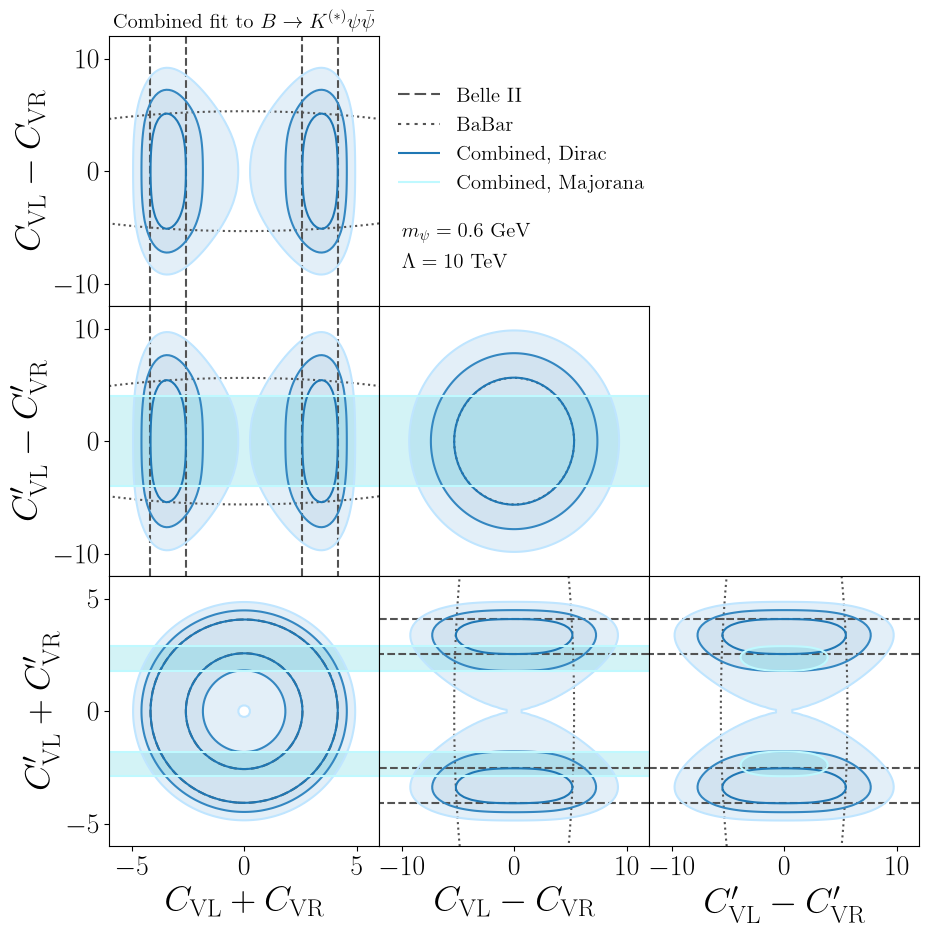

In [31]:
def fermion_panels(scans, file, compare = None):
    """Six panels of pairs of the vector and axial-vector fermion couplings, Dirac and Majorana.

    scans: {name: (Dirac scan, Majorana scan or None)}; compare: the same with the other Belle II
    likelihood, whose combined Dirac 1 sigma contours are overlaid as lines.
    """
    fig = plt.figure(figsize = (9, 9))
    VV, AV = r'$C_{\rm VL} + C_{\rm VR}$', r'$C_{\rm VL} - C_{\rm VR}$'
    VA, AA = r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$', r'$C_{\rm VL}^\prime - C_{\rm VR}^\prime$'
    panels = [  # axes rectangle, scan, x label, y label, hide x ticks, hide y ticks
        ([0.0, 0.0, 0.3, 0.3],  "fVVfAV", None, AV,   True,  False),
        ([0.0, -0.3, 0.3, 0.3], "fVVfAA", None, AA,   True,  False),
        ([0.0, -0.6, 0.3, 0.3], "fVVfVA", VV,   VA,   False, False),
        ([0.3, -0.3, 0.3, 0.3], "fAVfAA", None, None, False, True),
        ([0.3, -0.6, 0.3, 0.3], "fAVfVA", AV,   None, False, True),
        ([0.6, -0.6, 0.3, 0.3], "fAAfVA", AA,   None, False, True),
    ]
    label = 'Combined, Dirac' if compare is None else 'Combined, Dirac, Belle II public'
    axes = []
    for rect, name, xlabel, ylabel, hide_x, hide_y in panels:
        ax = fig.add_axes(rect)
        scan, scan_M = scans[name]
        handles = plot_contours(ax, scan, majorana = scan_M, combined_label = label)
        if compare is not None:
            handles['Combined, Dirac, lights'] = plot_combined_lines(ax, compare[name][0], levels = [2.3])
        if xlabel: ax.set_xlabel(xlabel, fontsize = 26)
        if ylabel: ax.set_ylabel(ylabel, fontsize = 26)
        if hide_x: ax.set_xticks([])
        if hide_y: ax.set_yticks([])
        axes.append(ax)
    axes[0].set_title(r'Combined fit to $B\to K^{(*)} \psi \bar{\psi}$', fontsize = 15)

    # Legends, attached to the bottom-left panel
    model = scans["fVVfVA"][0].models[0]
    blank_1, = axes[2].plot([], [], linewidth = 0)
    blank_2, = axes[2].plot([], [], linewidth = 0)
    leg1 = axes[2].legend([blank_1, blank_2], [r'$m_\psi = %g$ GeV' % model.mX, r'$\Lambda = %g$ TeV' % (model.Lambda / 1e3)],
                          loc = 'upper right', fontsize = 15, frameon = False, handlelength = 0, handletextpad = 0,
                          bbox_to_anchor = (1.63, 2.38))
    axes[2].legend(list(handles.values()), list(handles), loc = 'lower left', fontsize = 15, frameon = False,
                   bbox_to_anchor = (1.0, 2.35))
    axes[2].add_artist(leg1)

    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')


# Fermion pair: Dirac scans and their Majorana counterparts
fermion = {
    "fVVfAV": (scan_fVVfAV, None),
    "fVVfAA": (scan_fVVfAA, scan_fVVfAA_M),
    "fVVfVA": (scan_fVVfVA, scan_fVVfVA_M),
    "fAVfAA": (scan_fAVfAA, scan_fAVfAA_M),
    "fAVfVA": (scan_fAVfVA, scan_fAVfVA_M),
    "fAAfVA": (scan_fAAfVA, scan_fAAfVA_M),
}
fermion_panels(fermion, "3body_fermion_vectorcoupling.pdf")

With Belle II's public likelihood (dash-dot: the combined Dirac 1$\sigma$ contour with the lights Belle II likelihood):

psipsi, mX = 0.6: 100%|██████████| 10000/10000 [00:08<00:00, 1149.64it/s]


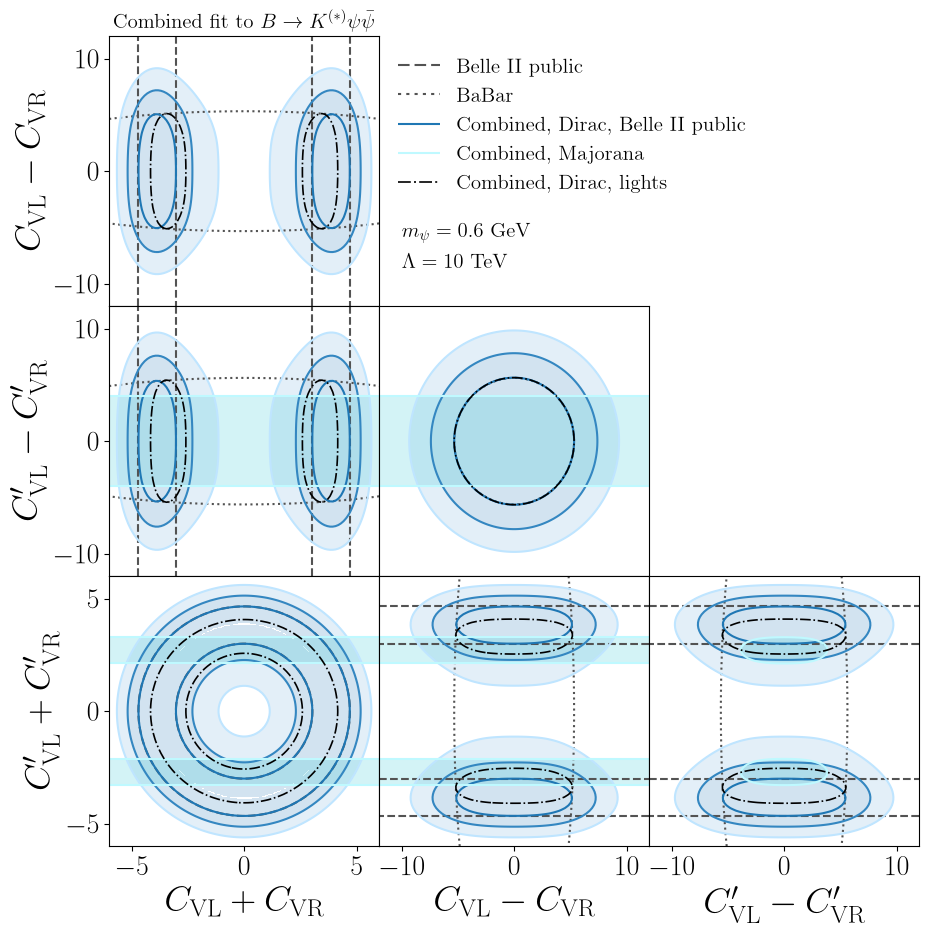

In [32]:
fermion_public = {name: (public(scan), None if scan_M is None else public(scan_M)) for name, (scan, scan_M) in fermion.items()}
fermion_panels(fermion_public, "3body_fermion_vectorcoupling_public.pdf", compare = fermion)

# Weak effective theory: Belle II's Fig. 3

Reproduction of Fig. 3 of Belle II's public likelihood paper ([arXiv:2507.12393](https://arxiv.org/abs/2507.12393)), without its one-dimensional panels: the WET couplings $C_{\rm VL} + C_{\rm VR}$, $C_{\rm SL} + C_{\rm SR}$ and $C_{\rm TL}$ of $B \to K \nu\bar\nu$ (its eq. 9; the `"nunu"` channel), fitted to the public Belle II likelihood with lights. The vector coupling rescales the SM, $(C_{\rm VL} + C_{\rm VR})^2 = \mu_{\rm SM}\, C_{\rm V,SM}^2$, so the three couplings are the three signal strengths of the fit; each panel scans two of them with the third **profiled**, i.e. fitted at each point (`profile_logLL_strengths`), as Belle II marginalises over it. Unlike the scenario scans above, a panel is therefore not a slice with the third coupling at zero: where the two scanned couplings cannot explain Belle II's excess, the third can (here mostly $C_{\rm TL}$). The rate depends only on the squares of the couplings, so the likelihood is symmetric under the sign of each: it is computed for couplings $\geq 0$ and mirrored (Belle II symmetrised its samples in the same way).

Differences from Belle II's figure:
- the likelihood is the ITA only (Belle II: ITA and HTA combined);
- profile likelihood regions ($-2\Delta\ln L = 2.30, 5.99$: 68% and 95% for two parameters) instead of Bayesian marginal posteriors with flat priors;
- lights form factors (GRDV; within 2% of Belle II's EOS form factors).

The couplings are normalised as in the paper and EOS, with $\alpha_e(m_b) = 1/133$ in eq. 7, so that $C_{\rm V,SM} = 6.60$ (EOS: 6.61).

In [33]:
from lights.fits import profile_logLL_strengths
from lights.constants import ALPHA, ALPHA_MB, Xt, SWsq

CV_SM = Xt / SWsq * ALPHA / ALPHA_MB      # 6.60: |C_V|^2 = mu_SM CV_SM^2, in the WET normalisation (alpha_e(m_b))
WET_S, WET_T = Model("nunu", 0., CSL = 1.), Model("nunu", 0., CTL = 1.)   # x1 = |C_SL + C_SR|, x2 = |C_TL|
C_wet = np.linspace(0, 32, 81)                                          # couplings >= 0, covering the 95% regions
to_x = {"x0": (C_wet / CV_SM)**2, "x1": C_wet, "x2": C_wet}
wet = {pair: profile_logLL_strengths("BelleII_public", WET_S, WET_T, pair, to_x[pair[0]], to_x[pair[1]])
       for pair in (("x0", "x1"), ("x0", "x2"), ("x1", "x2"))}

# The likelihood depends on the squares of the couplings: mirror the grids (computed for C >= 0) to C < 0
C_full = np.concatenate((-C_wet[:0:-1], C_wet))
def mirror(grid):
    "A grid over couplings >= 0, indexed [b, a], extended to negative couplings."
    grid = np.concatenate((grid[:, :0:-1], grid), axis = 1)
    return np.concatenate((grid[:0:-1], grid), axis = 0)
wet_full = {pair: mirror(grid) for pair, grid in wet.items()}

BelleII_public, scan ('x1', 'x2'): 100%|██████████| 6561/6561 [00:02<00:00, 3277.80it/s]


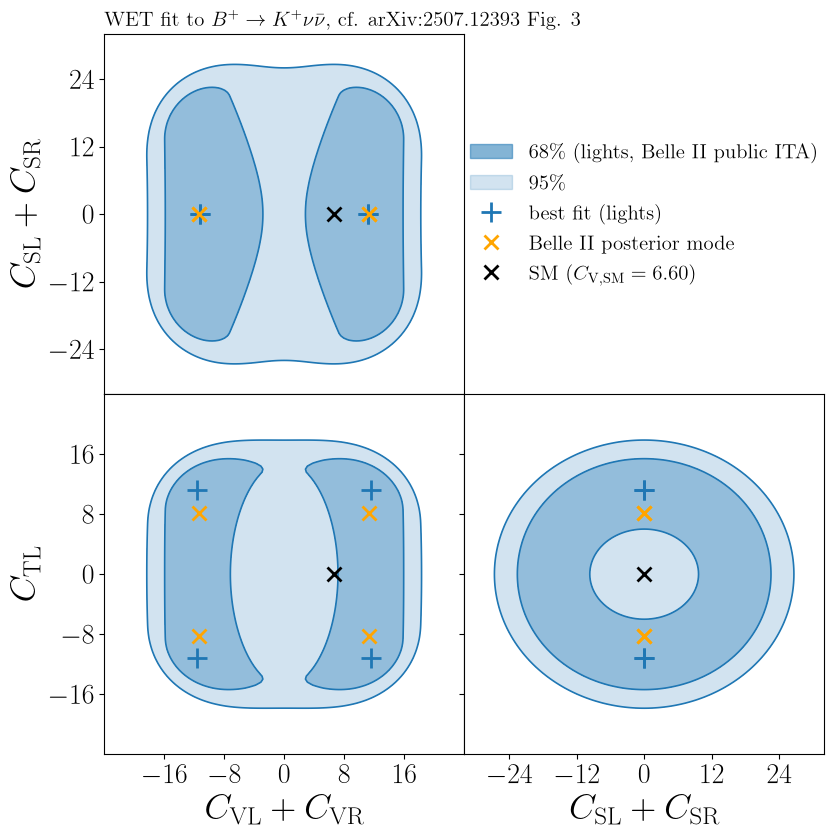

In [34]:
labels = {"x0": r'$C_{\rm VL} + C_{\rm VR}$', "x1": r'$C_{\rm SL} + C_{\rm SR}$', "x2": r'$C_{\rm TL}$'}
ranges = {"x0": 24, "x1": 32, "x2": 24}                                # axis ranges, -range ... range
ticks = {"x0": 8, "x1": 12, "x2": 8}                                   # tick spacing
SM = {"x0": CV_SM, "x1": 0, "x2": 0}
mode_belle = {"x0": 11.3, "x1": 0.0, "x2": 8.2}                       # posterior mode, and its mirror images
signs = [(1, 1), (1, -1), (-1, 1), (-1, -1)]

fig = plt.figure(figsize = (9, 9))
panels = [  # axes rectangle, scanned pair, hide x ticks, hide y ticks
    ([0.0, 0.4, 0.4, 0.4], ("x0", "x1"), True,  False),
    ([0.0, 0.0, 0.4, 0.4], ("x0", "x2"), False, False),
    ([0.4, 0.0, 0.4, 0.4], ("x1", "x2"), False, True),
]
X, Y = np.meshgrid(C_full, C_full)
axes = []
for rect, pair, hide_x, hide_y in panels:
    ax = fig.add_axes(rect)
    grid = wet_full[pair]
    ax.contourf(X, Y, grid, levels = [0, 5.99], colors = 'C0', alpha = 0.2)
    ax.contourf(X, Y, grid, levels = [0, 2.30], colors = 'C0', alpha = 0.35)
    ax.contour(X, Y, grid, levels = [2.30, 5.99], colors = 'C0', linewidths = 1.2)
    g = wet[pair]
    j, i = np.unravel_index(np.argmin(g), g.shape)                    # best fit (couplings >= 0) and its mirror images
    for sa, sb in signs:
        best, = ax.plot(sa * C_wet[i], sb * C_wet[j], '+', color = 'C0', ms = 14, mew = 2)
        mode, = ax.plot(sa * mode_belle[pair[0]], sb * mode_belle[pair[1]], 'x', color = 'orange', ms = 10, mew = 2)
    sm, = ax.plot(SM[pair[0]], SM[pair[1]], 'x', color = 'k', ms = 10, mew = 2)
    ax.set_xlim(-ranges[pair[0]], ranges[pair[0]])
    ax.set_ylim(-ranges[pair[1]], ranges[pair[1]])
    for axis, name in ((ax.xaxis, pair[0]), (ax.yaxis, pair[1])):
        axis.set_ticks(np.arange(-ranges[name] // ticks[name] * ticks[name], ranges[name], ticks[name])[1:])
    if hide_x: ax.set_xticklabels([])
    else: ax.set_xlabel(labels[pair[0]], fontsize = 26)
    if hide_y: ax.set_yticklabels([])
    else: ax.set_ylabel(labels[pair[1]], fontsize = 26)
    axes.append(ax)
axes[0].set_title(r'WET fit to $B^+\to K^+\nu\bar\nu$, cf. arXiv:2507.12393 Fig. 3', fontsize = 15, loc = 'left')

regions = [plt.Rectangle((0, 0), 1, 1, color = 'C0', alpha = a) for a in (0.55, 0.2)]
fig.legend(regions + [best, mode, sm],
           [r'68\% (lights, Belle II public ITA)', r'95\%', 'best fit (lights)', 'Belle II posterior mode',
            r'SM ($C_{\rm V,SM} = 6.60$)'],
           loc = 'center', bbox_to_anchor = (0.6, 0.6), fontsize = 15, frameon = False)
plt.savefig(SAVE_DIR / "WET_belle2_fig3.pdf", bbox_inches = 'tight')

## The same fit with the lights Belle II likelihood

The WET fit above, with the lights Belle II likelihood (`"BelleII"`: ITA, 20 bins of $q^2_{\rm rec}$) instead of Belle II's public likelihood; the same templates, scans and axis ranges.

In [35]:
wet_lights = {pair: profile_logLL_strengths("BelleII", WET_S, WET_T, pair, to_x[pair[0]], to_x[pair[1]])
              for pair in (("x0", "x1"), ("x0", "x2"), ("x1", "x2"))}
wet_lights_full = {pair: mirror(grid) for pair, grid in wet_lights.items()}

BelleII, scan ('x1', 'x2'): 100%|██████████| 6561/6561 [00:01<00:00, 6538.32it/s]


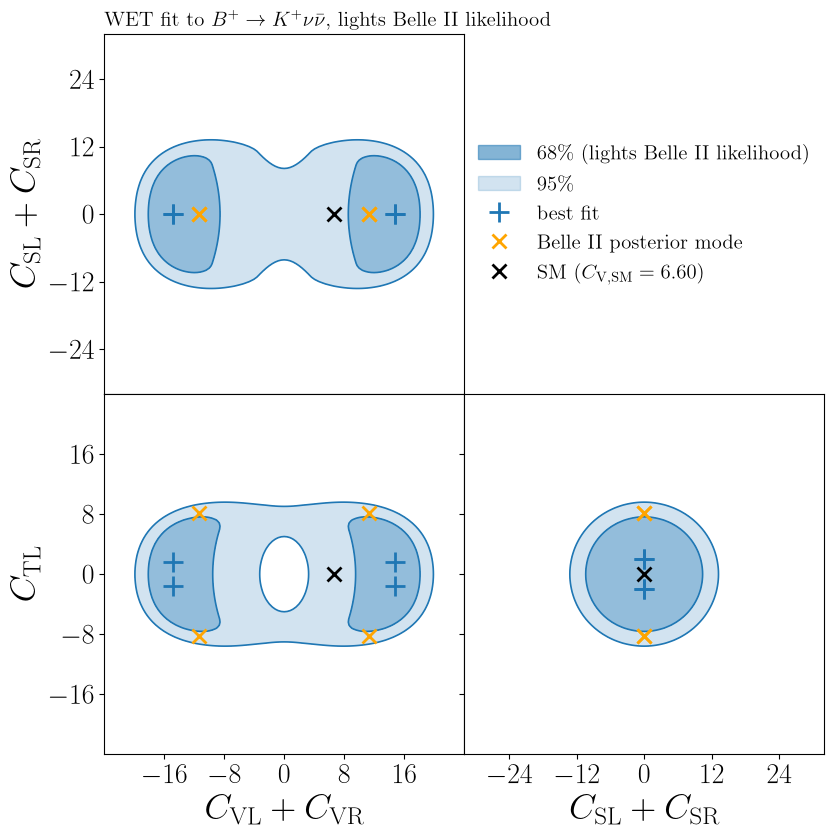

In [36]:
def wet_figure(grids, grids_full, likelihood, title, file):
    "The three WET panels (as above): 68% and 95% regions of the mirrored grids, best fit, Belle II's mode and the SM."
    fig = plt.figure(figsize = (9, 9))
    panels = [  # axes rectangle, scanned pair, hide x ticks, hide y ticks
        ([0.0, 0.4, 0.4, 0.4], ("x0", "x1"), True,  False),
        ([0.0, 0.0, 0.4, 0.4], ("x0", "x2"), False, False),
        ([0.4, 0.0, 0.4, 0.4], ("x1", "x2"), False, True),
    ]
    X, Y = np.meshgrid(C_full, C_full)
    axes = []
    for rect, pair, hide_x, hide_y in panels:
        ax = fig.add_axes(rect)
        ax.contourf(X, Y, grids_full[pair], levels = [0, 5.99], colors = 'C0', alpha = 0.2)
        ax.contourf(X, Y, grids_full[pair], levels = [0, 2.30], colors = 'C0', alpha = 0.35)
        ax.contour(X, Y, grids_full[pair], levels = [2.30, 5.99], colors = 'C0', linewidths = 1.2)
        j, i = np.unravel_index(np.argmin(grids[pair]), grids[pair].shape)   # best fit (couplings >= 0) and mirror images
        for sa, sb in signs:
            best, = ax.plot(sa * C_wet[i], sb * C_wet[j], '+', color = 'C0', ms = 14, mew = 2)
            mode, = ax.plot(sa * mode_belle[pair[0]], sb * mode_belle[pair[1]], 'x', color = 'orange', ms = 10, mew = 2)
        sm, = ax.plot(SM[pair[0]], SM[pair[1]], 'x', color = 'k', ms = 10, mew = 2)
        ax.set_xlim(-ranges[pair[0]], ranges[pair[0]])
        ax.set_ylim(-ranges[pair[1]], ranges[pair[1]])
        for axis, name in ((ax.xaxis, pair[0]), (ax.yaxis, pair[1])):
            axis.set_ticks(np.arange(-ranges[name] // ticks[name] * ticks[name], ranges[name], ticks[name])[1:])
        if hide_x: ax.set_xticklabels([])
        else: ax.set_xlabel(labels[pair[0]], fontsize = 26)
        if hide_y: ax.set_yticklabels([])
        else: ax.set_ylabel(labels[pair[1]], fontsize = 26)
        axes.append(ax)
    axes[0].set_title(title, fontsize = 15, loc = 'left')
    regions = [plt.Rectangle((0, 0), 1, 1, color = 'C0', alpha = a) for a in (0.55, 0.2)]
    fig.legend(regions + [best, mode, sm],
               [r'68\% (' + likelihood + ')', r'95\%', 'best fit', 'Belle II posterior mode', r'SM ($C_{\rm V,SM} = 6.60$)'],
               loc = 'center', bbox_to_anchor = (0.6, 0.6), fontsize = 15, frameon = False)
    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')

wet_figure(wet_lights, wet_lights_full, 'lights Belle II likelihood',
           r'WET fit to $B^+\to K^+\nu\bar\nu$, lights Belle II likelihood', "WET_lights.pdf")

# Weak effective theory: all couplings, Belle II and BaBar

The WET fit extended to all couplings, with BaBar's $B^0\to K^{*0}\nu\bar\nu$ added to Belle II's $B^+\to K^+\nu\bar\nu$. $B\to K$ depends on $C_{\rm VL} + C_{\rm VR}$, $C_{\rm SL} + C_{\rm SR}$ and $C_{\rm TL}$; $B\to K^*$ also on $C_{\rm VL} - C_{\rm VR}$ and $C_{\rm SL} - C_{\rm SR}$. For massless neutrinos the rate is a sum of five positive terms, one per combination, without interference between them, so the five combinations are fitted together (`fit_WET`, `profile_logLL_WET`). The SM is included in the vector couplings ($C_{\rm VL} \pm C_{\rm VR} = C_{\rm V,SM} = 6.60$ in the SM), so their interference with it is included, and $C_{\rm VL} - C_{\rm VR}$ is not tied to $C_{\rm VL} + C_{\rm VR}$ (unlike a fit of $\mu_{\rm SM}$, which rescales both, i.e. $C_{\rm VR} = 0$).

Each panel scans two couplings with the other three **profiled** (fitted at each point), as in Fig. 3 above but unlike the scenario scans, which are slices with all other couplings zero. The shape of a panel therefore also reflects what the profiled couplings do: e.g. without BaBar, $C_{\rm TL} \approx 10-14$ can absorb Belle II's excess where $C_{\rm VL} + C_{\rm VR}$ and $C_{\rm SL} + C_{\rm SR}$ are small, so the Fig. 3 panels allow that region; BaBar's $B\to K^*$, which the tensor operator enhances strongly, limits $|C_{\rm TL}| \lesssim 4$, so here the excess must come from the scanned couplings and the region near zero is disfavoured. Further, the likelihood depends on the squares of the five combinations, so the grids are computed for couplings $\geq 0$ and mirrored. Both Belle II likelihoods are shown, each combined with BaBar (LEP does not constrain $B_s \to \nu\bar\nu$).

In [37]:
from lights.fits import WET_COUPLINGS, fit_WET, profile_logLL_WET
from lights.constants import CVL_SM

wet_labels = {"V+": r'$C_{\rm VL} + C_{\rm VR}$', "V-": r'$C_{\rm VL} - C_{\rm VR}$', "S+": r'$C_{\rm SL} + C_{\rm SR}$',
              "S-": r'$C_{\rm SL} - C_{\rm SR}$', "T": r'$C_{\rm TL}$'}
wet_ranges = {"V+": 24, "V-": 40, "S+": 32, "S-": 56, "T": 10}   # axis ranges (-range ... range), covering the 95% regions
wet_ticks = {"V+": 8, "V-": 16, "S+": 12, "S-": 24, "T": 4}
wet_SM = dict(zip(WET_COUPLINGS, (CVL_SM, CVL_SM, 0, 0, 0)))
columns, rows = ("V+", "V-", "S+", "S-"), ("T", "S-", "S+", "V-")    # x axes, left to right; y axes, bottom to top
wet_pairs = [(a, b) for a in columns for b in rows if WET_COUPLINGS.index(a) < WET_COUPLINGS.index(b)]

wet_vals = {c: np.linspace(0, r, 81) for c, r in wet_ranges.items()}           # couplings >= 0
wet_vals_full = {c: np.concatenate((-v[:0:-1], v)) for c, v in wet_vals.items()}
wet_all = {}
for experiment in ("combined_public", "combined"):
    fit = fit_WET(experiment)
    print(f"{experiment}: best fit", {c: round(v, 2) for c, v in fit.couplings.items()}, f"-2 ln(L / L_SM) = {fit.delta_chi2:.1f}")
    wet_all[experiment] = {pair: profile_logLL_WET(experiment, pair, wet_vals[pair[0]], wet_vals[pair[1]])
                           for pair in wet_pairs}

combined_public: best fit {'V+': 12.24, 'V-': 0.09, 'S+': 16.59, 'S-': 0.1, 'T': 2.3} -2 ln(L / L_SM) = -13.0


combined: best fit {'V+': 14.58, 'V-': 0.08, 'S+': 0.01, 'S-': 0.02, 'T': 2.21} -2 ln(L / L_SM) = -7.0


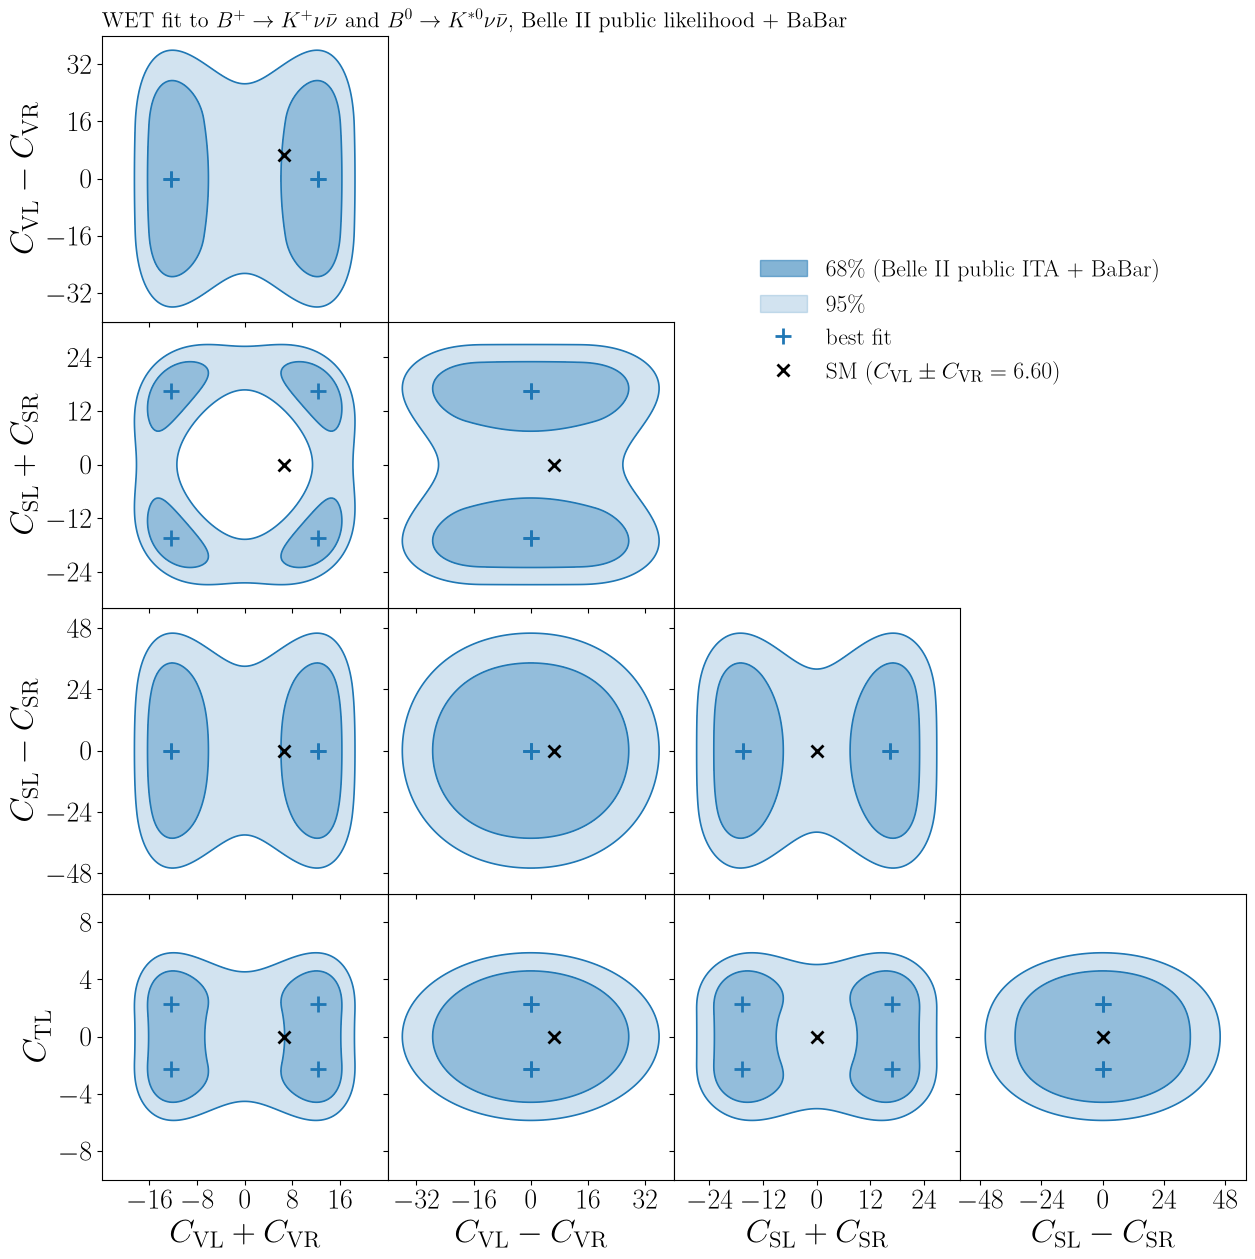

In [38]:
def wet_corner(grids, likelihood, title, file):
    """The ten WET panels: each pair of couplings (columns: x, rows: y), with the 68% and 95% regions of the
    mirrored grids, the best fit (and its mirror images) and the SM."""
    fig = plt.figure(figsize = (13, 13))
    size = 0.22
    for (a, b), grid in grids.items():
        i, r = columns.index(a), rows.index(b)
        ax = fig.add_axes([i * size, r * size, size, size])
        X, Y = np.meshgrid(wet_vals_full[a], wet_vals_full[b])
        full = mirror(grid)
        ax.contourf(X, Y, full, levels = [0, 5.99], colors = 'C0', alpha = 0.2)
        ax.contourf(X, Y, full, levels = [0, 2.30], colors = 'C0', alpha = 0.35)
        ax.contour(X, Y, full, levels = [2.30, 5.99], colors = 'C0', linewidths = 1.2)
        jb, ja = np.unravel_index(np.argmin(grid), grid.shape)     # best fit (couplings >= 0) and its mirror images
        for sa, sb in signs:
            best, = ax.plot(sa * wet_vals[a][ja], sb * wet_vals[b][jb], '+', color = 'C0', ms = 12, mew = 2)
        sm, = ax.plot(wet_SM[a], wet_SM[b], 'x', color = 'k', ms = 9, mew = 2)
        ax.set_xlim(-wet_ranges[a], wet_ranges[a])
        ax.set_ylim(-wet_ranges[b], wet_ranges[b])
        for axis, name in ((ax.xaxis, a), (ax.yaxis, b)):
            axis.set_ticks(np.arange(-wet_ranges[name] // wet_ticks[name] * wet_ticks[name], wet_ranges[name], wet_ticks[name])[1:])
        if r > 0: ax.set_xticklabels([])
        else: ax.set_xlabel(wet_labels[a], fontsize = 24)
        if i > 0: ax.set_yticklabels([])
        else: ax.set_ylabel(wet_labels[b], fontsize = 24)
        if (i, r) == (0, len(rows) - 1):
            ax.set_title(title, fontsize = 16, loc = 'left')
    regions = [plt.Rectangle((0, 0), 1, 1, color = 'C0', alpha = a) for a in (0.55, 0.2)]
    fig.legend(regions + [best, sm], [r'68\% (' + likelihood + ')', r'95\%', 'best fit', r'SM ($C_{\rm VL} \pm C_{\rm VR} = 6.60$)'],
               loc = 'center', bbox_to_anchor = (0.66, 0.66), fontsize = 17, frameon = False)
    plt.savefig(SAVE_DIR / file, bbox_inches = 'tight')

wet_corner(wet_all["combined_public"], 'Belle II public ITA + BaBar',
           r'WET fit to $B^+\to K^+\nu\bar\nu$ and $B^0\to K^{*0}\nu\bar\nu$, Belle II public likelihood + BaBar',
           "WET_all_public.pdf")

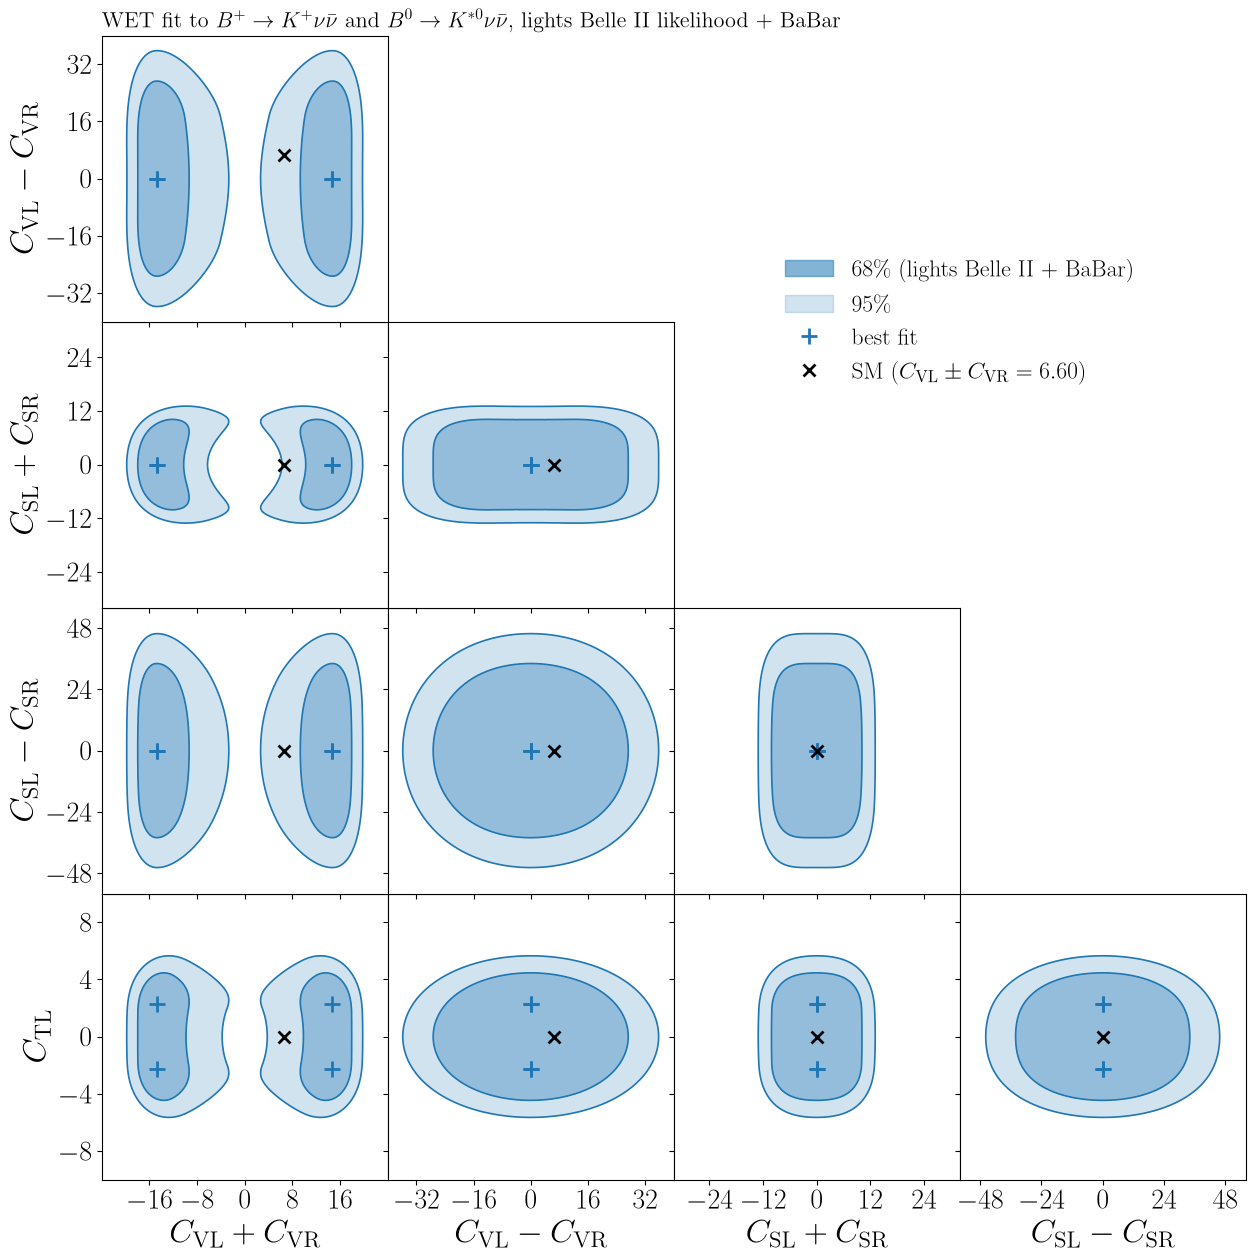

In [39]:
wet_corner(wet_all["combined"], 'lights Belle II + BaBar',
           r'WET fit to $B^+\to K^+\nu\bar\nu$ and $B^0\to K^{*0}\nu\bar\nu$, lights Belle II likelihood + BaBar',
           "WET_all_lights.pdf")